# 02 · Exploratory Data Analysis & Statistical Tests
Descriptive statistics, business trends and formal hypothesis tests. Figures are also saved to `reports/figures/` for the report.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60); pd.set_option("display.float_format", "{:,.3f}".format)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)


In [2]:
master = pd.read_parquet(ROOT / "data/processed/master_orders.parquet")
dlv = master[master.is_delivered == 1].copy()          # delivered orders (used for most analyses)
print(f"all orders: {len(master):,} | delivered: {len(dlv):,}")


all orders: 98,500 | delivered: 96,305


## 1. Headline KPIs

In [3]:
kpi = {
    "Orders": len(master),
    "Unique customers": master.customer_unique_id.nunique(),
    "Sellers": master.seller_id.nunique(),
    "Revenue (BRL, items+freight)": master.order_value.sum(),
    "Average order value (BRL)": master.order_value.mean(),
    "Average review score": master.review_score.mean(),
    "Late delivery rate (delivered)": dlv.is_late.mean(),
    "Bad review rate (1-3 stars)": master.bad_review.mean(),
    "Repeat-customer rate": (master.groupby("customer_unique_id").size() > 1).mean(),
}
pd.Series(kpi).to_frame("value")

,value
Orders,"98,500.000"
Unique customers,"95,257.000"
Sellers,"3,084.000"
"Revenue (BRL, items+freight)","15,820,423.220"
Average order value (BRL),160.613
Average review score,4.104
Late delivery rate (delivered),0.068
Bad review rate (1-3 stars),0.225
Repeat-customer rate,0.031


## 2. Descriptive statistics (central tendency, spread, shape)

In [4]:
num = ["order_value", "total_price", "total_freight", "freight_ratio", "n_items", "payment_installments",
       "distance_km", "estimated_delivery_days", "actual_delivery_days", "delay_days", "review_score"]
desc = dlv[num].describe(percentiles=[.25, .5, .75, .95]).T
desc["skew"] = dlv[num].skew(); desc["kurtosis"] = dlv[num].kurt()
desc

,count,mean,std,min,25%,50%,75%,95%,max,skew,kurtosis
order_value,"96,305.000",159.861,218.924,9.590,61.840,105.280,176.330,446.534,"13,664.080",9.367,249.133
total_price,"96,305.000",137.078,209.169,0.850,45.900,86.580,149.900,399.000,"13,440.000",9.884,276.842
total_freight,"96,305.000",22.783,21.567,0.000,13.840,17.170,24.010,54.778,"1,794.960",12.283,586.180
freight_ratio,"96,305.000",0.209,0.126,0.000,0.117,0.183,0.276,0.456,0.955,1.062,1.203
n_items,"96,305.000",1.142,0.539,1.000,1.000,1.000,1.000,2.000,21.000,7.561,116.467
payment_installments,"96,304.000",2.928,2.713,1.000,1.000,2.000,4.000,10.000,24.000,1.603,2.379
distance_km,"96,305.000",601.118,592.102,0.000,186.535,434.834,801.254,"2,095.234","3,398.486",1.653,2.504
estimated_delivery_days,"96,305.000",23.739,8.759,2.008,18.333,23.233,28.408,38.418,155.135,0.906,4.307
actual_delivery_days,"96,305.000",12.567,9.550,0.533,6.774,10.226,15.731,29.292,209.629,3.833,39.306
delay_days,"96,305.000",-11.172,10.186,-146.016,-16.242,-11.933,-6.387,3.822,188.975,2.013,28.063


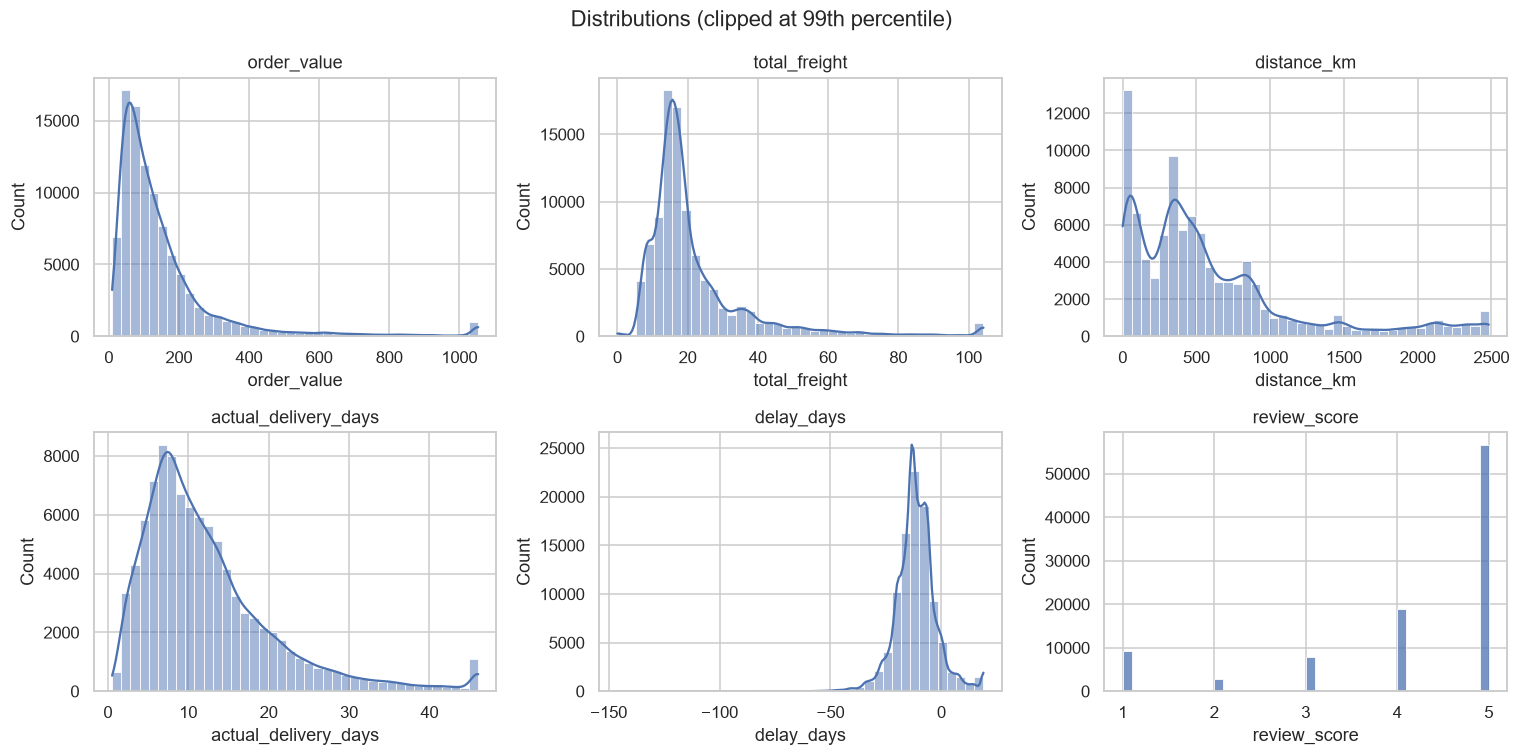

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, ["order_value", "total_freight", "distance_km", "actual_delivery_days", "delay_days", "review_score"]):
    data = dlv[c].clip(upper=dlv[c].quantile(.99))
    sns.histplot(data, bins=40, ax=ax, kde=c != "review_score"); ax.set_title(c)
plt.suptitle("Distributions (clipped at 99th percentile)"); plt.tight_layout()
plt.savefig(FIG / "distributions.png"); plt.show()

Money, weight and distance are **strongly right-skewed** (skew > 3) → we apply `log1p` before linear / Naive Bayes models.

## 3. Sales trends

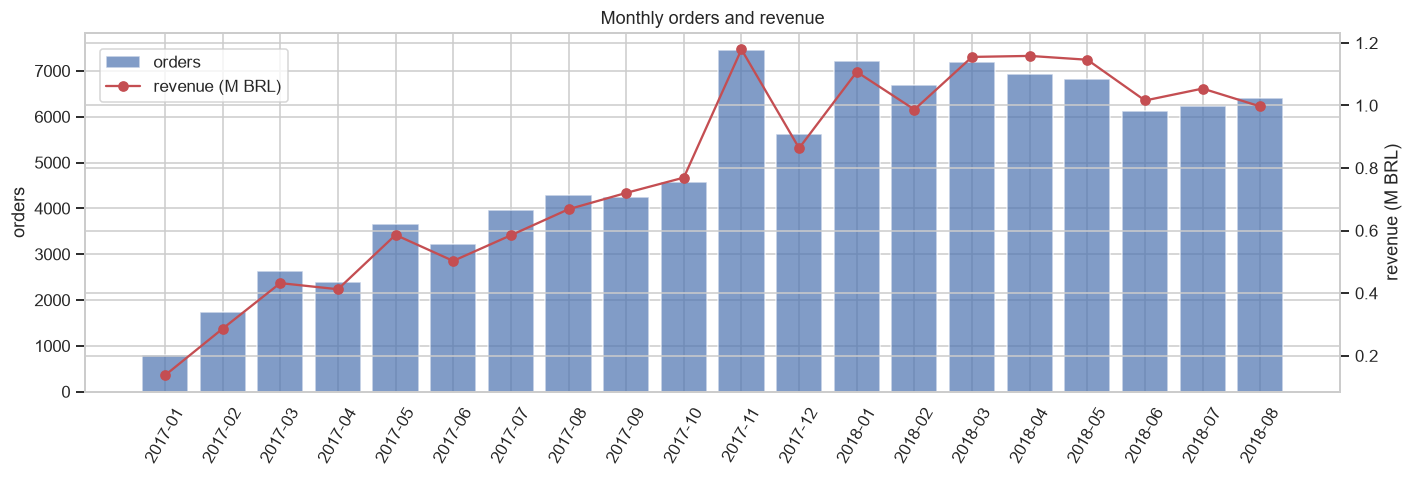

,orders,revenue,aov,orders_growth_%
purchase_year_month,,,,
2018-01,7220,"1,107,301.890",153.366,28.378
2018-02,6694,"986,908.960",147.432,-7.285
2018-03,7188,"1,155,126.820",160.702,7.380
2018-04,6926,"1,158,368.700",167.249,-3.645
2018-05,6823,"1,146,080.420",167.973,-1.487
2018-06,6114,"1,015,821.080",166.147,-10.391
2018-07,6236,"1,053,959.960",169.012,1.995
2018-08,6407,"996,833.290",155.585,2.742


In [6]:
m = master[master.order_purchase_timestamp >= "2017-01-01"].groupby("purchase_year_month").agg(
    orders=("order_id", "size"), revenue=("order_value", "sum"), aov=("order_value", "mean"))
m = m[m.index <= "2018-08"]
m["orders_growth_%"] = m.orders.pct_change() * 100
fig, ax = plt.subplots(figsize=(13, 4.5)); ax2 = ax.twinx()
ax.bar(m.index, m.orders, color="C0", alpha=.7, label="orders"); ax2.plot(m.index, m.revenue / 1e6, "C3-o", label="revenue (M BRL)")
ax.set_ylabel("orders"); ax2.set_ylabel("revenue (M BRL)"); ax.tick_params(axis="x", rotation=60)
ax.set_title("Monthly orders and revenue"); fig.legend(loc="upper left", bbox_to_anchor=(.07, .9))
plt.tight_layout(); plt.savefig(FIG / "monthly_trend.png"); plt.show()
m.tail(8)

Top 5 days by orders:


,orders
purchase_date,
2017-11-24,1166
2017-11-25,498
2017-11-27,400
2017-11-26,388
2017-11-28,376


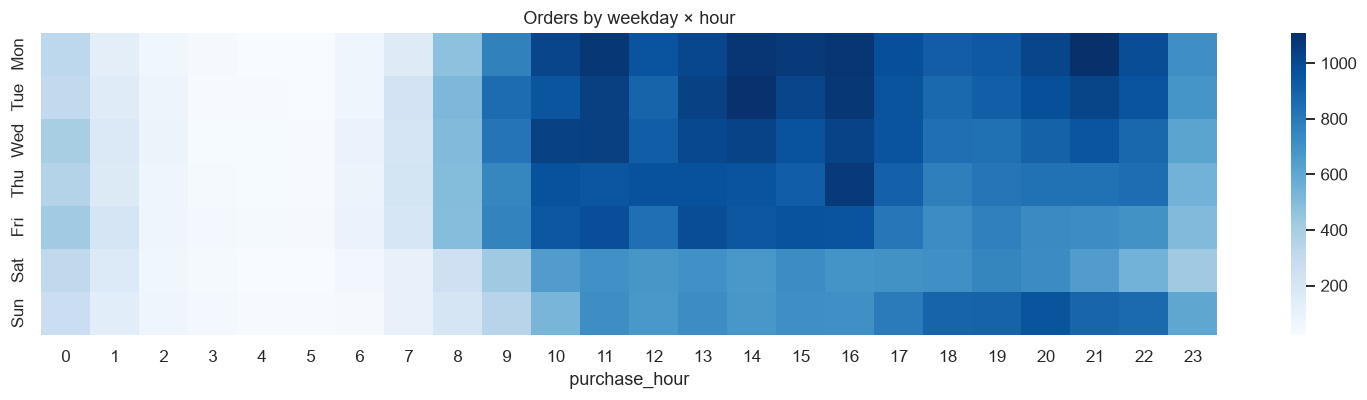

In [7]:
daily = master.groupby("purchase_date").size()
print("Top 5 days by orders:"); display(daily.sort_values(ascending=False).head(5).to_frame("orders"))
pivot = master.pivot_table(index="purchase_weekday", columns="purchase_hour", values="order_id", aggfunc="count")
pivot.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.figure(figsize=(14, 3.8)); sns.heatmap(pivot, cmap="Blues"); plt.title("Orders by weekday × hour")
plt.tight_layout(); plt.savefig(FIG / "weekday_hour.png"); plt.show()

**Trend findings**
* Orders grew ~**10× from Jan-2017 to 2018**, then plateaued around 6–7k orders/month.
* **24-Nov-2017 (Black Friday)** is the busiest day in the dataset by far.
* Customers buy mostly **Mon–Fri, 10h–22h**; weekends and nights are quiet.

## 4. Customers & geography

,orders,revenue,avg_delivery_days,late_rate,avg_review,share_%
customer_state,,,,,,
SP,40442,"5,762,397.580",8.766,0.045,4.246,41.994
RJ,12331,"2,053,262.590",15.320,0.121,3.965,12.804
MG,11332,"1,815,477.750",12.021,0.046,4.192,11.767
RS,5328,"859,012.330",15.321,0.061,4.185,5.532
PR,4912,"779,690.750",12.003,0.041,4.239,5.100
SC,3536,"593,727.660",14.976,0.082,4.132,3.672
BA,3252,"590,339.730",19.337,0.121,3.931,3.377
DF,2077,"345,710.760",12.978,0.057,4.131,2.157
ES,1989,"316,048.810",15.807,0.108,4.076,2.065


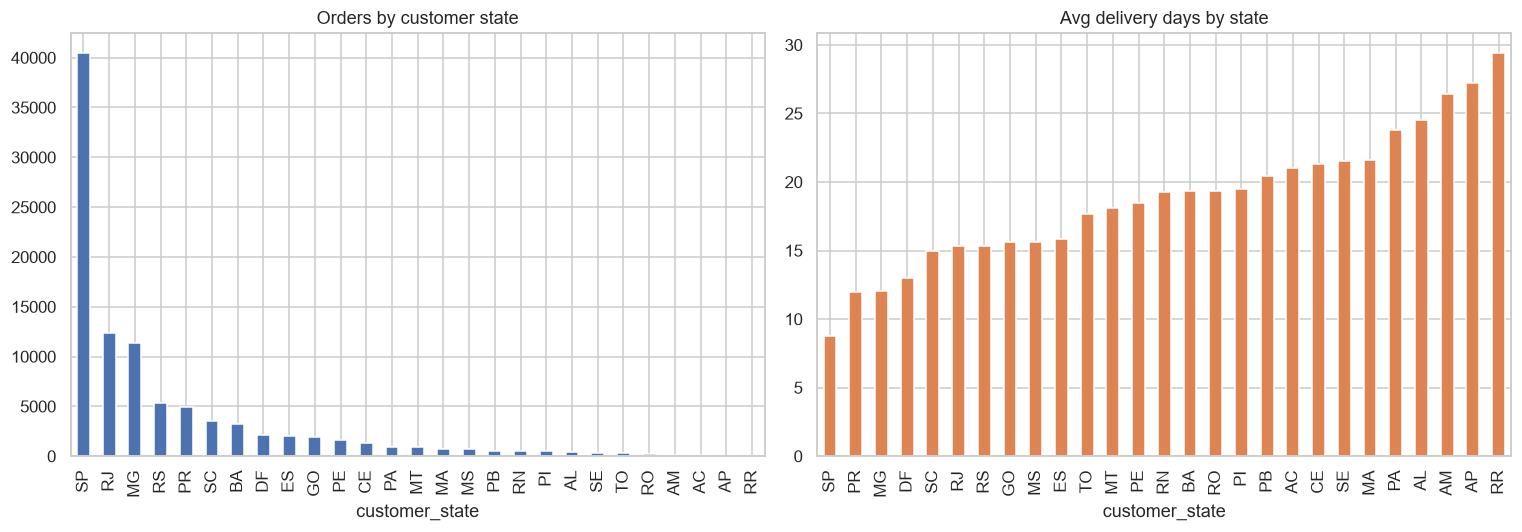

In [8]:
st = dlv.groupby("customer_state").agg(orders=("order_id", "size"), revenue=("order_value", "sum"),
    avg_delivery_days=("actual_delivery_days", "mean"), late_rate=("is_late", "mean"),
    avg_review=("review_score", "mean")).sort_values("orders", ascending=False)
st["share_%"] = st.orders / st.orders.sum() * 100
display(st.head(10))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
st.orders.plot.bar(ax=axes[0], color="C0", title="Orders by customer state")
st.sort_values("avg_delivery_days").avg_delivery_days.plot.bar(ax=axes[1], color="C1", title="Avg delivery days by state")
plt.tight_layout(); plt.savefig(FIG / "states.png"); plt.show()

In [9]:
# RFM (Recency, Frequency, Monetary) per unique customer
ref = master.order_purchase_timestamp.max() + pd.Timedelta(days=1)
rfm = master.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda s: (ref - s.max()).days),
    frequency=("order_id", "nunique"), monetary=("order_value", "sum"))
rfm["R"] = pd.qcut(rfm.recency, 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = np.where(rfm.frequency > 1, 4, 1)
rfm["M"] = pd.qcut(rfm.monetary, 4, labels=[1, 2, 3, 4]).astype(int)
rfm["segment"] = np.select([(rfm.R >= 3) & (rfm.F == 4), (rfm.R >= 3) & (rfm.M >= 3), rfm.R >= 3, rfm.M >= 3],
                           ["Loyal", "Recent big spender", "Recent", "Lapsed big spender"], "Lapsed / low value")
display(rfm.segment.value_counts(normalize=True).mul(100).round(1).to_frame("% customers"))
print(f"Customers with more than one order: {(rfm.frequency > 1).mean():.2%}")

,% customers
segment,
Lapsed / low value,25.500
Lapsed big spender,24.500
Recent,24.300
Recent big spender,24.000
Loyal,1.700


Customers with more than one order: 3.06%


Only **~3% of customers come back** → retention is the biggest business opportunity; satisfaction (next sections) drives it.

## 5. Products

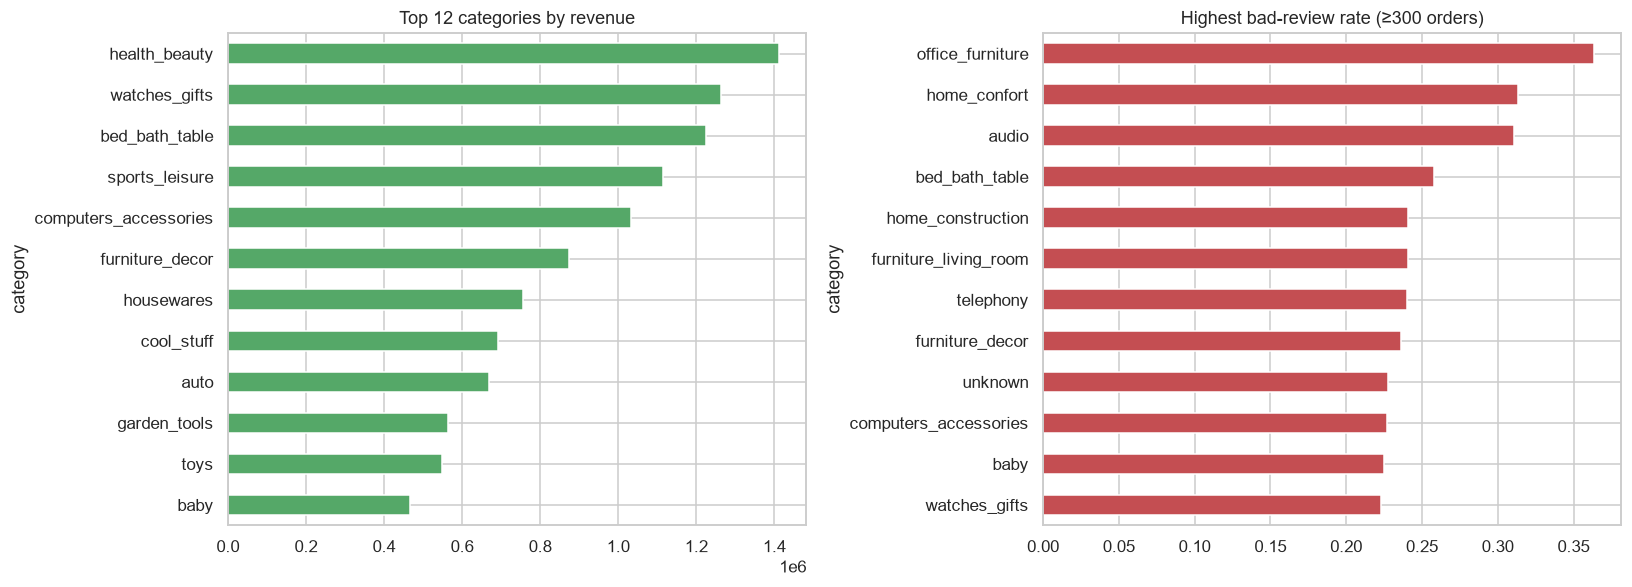

In [10]:
cat = dlv.groupby("category").agg(orders=("order_id", "size"), revenue=("order_value", "sum"),
    avg_price=("total_price", "mean"), bad_rate=("bad_review", "mean"), late_rate=("is_late", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cat.revenue.nlargest(12).sort_values().plot.barh(ax=axes[0], color="C2", title="Top 12 categories by revenue")
cat[cat.orders >= 300].bad_rate.nlargest(12).sort_values().plot.barh(ax=axes[1], color="C3", title="Highest bad-review rate (≥300 orders)")
plt.tight_layout(); plt.savefig(FIG / "categories.png"); plt.show()

## 6. Delivery performance

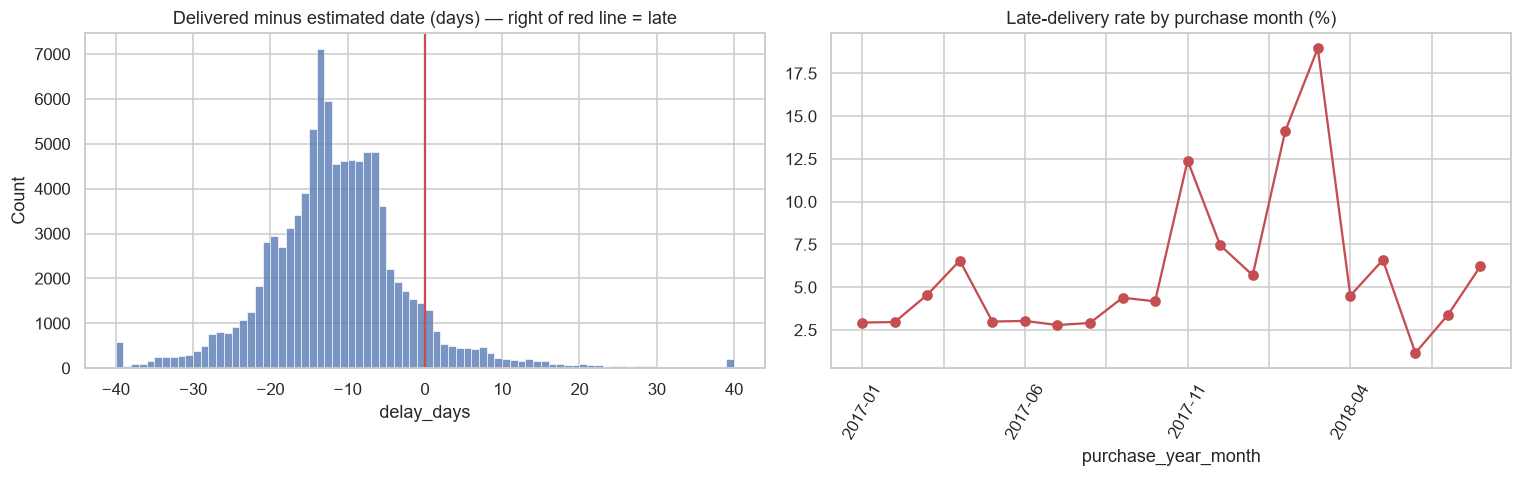

Olist estimates are conservative: median order arrives 11.9 days EARLY; 6.8% arrive late.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(dlv.delay_days.clip(-40, 40), bins=80, ax=axes[0]); axes[0].axvline(0, color="r")
axes[0].set_title("Delivered minus estimated date (days) — right of red line = late")
lt = dlv[dlv.order_purchase_timestamp >= "2017-01-01"].groupby("purchase_year_month").is_late.mean() * 100
lt.plot(ax=axes[1], marker="o", color="C3", title="Late-delivery rate by purchase month (%)"); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG / "delivery.png"); plt.show()
print(f"Olist estimates are conservative: median order arrives {-dlv.delay_days.median():.1f} days EARLY; {dlv.is_late.mean():.1%} arrive late.")

Late rate spikes after **Black Friday (Nov-2017)** and in **Feb–Mar 2018** (carrier strikes/peak load) → shows a concept drift we must respect with a **time-based train/test split**.

## 7. Reviews & satisfaction — the key relationship

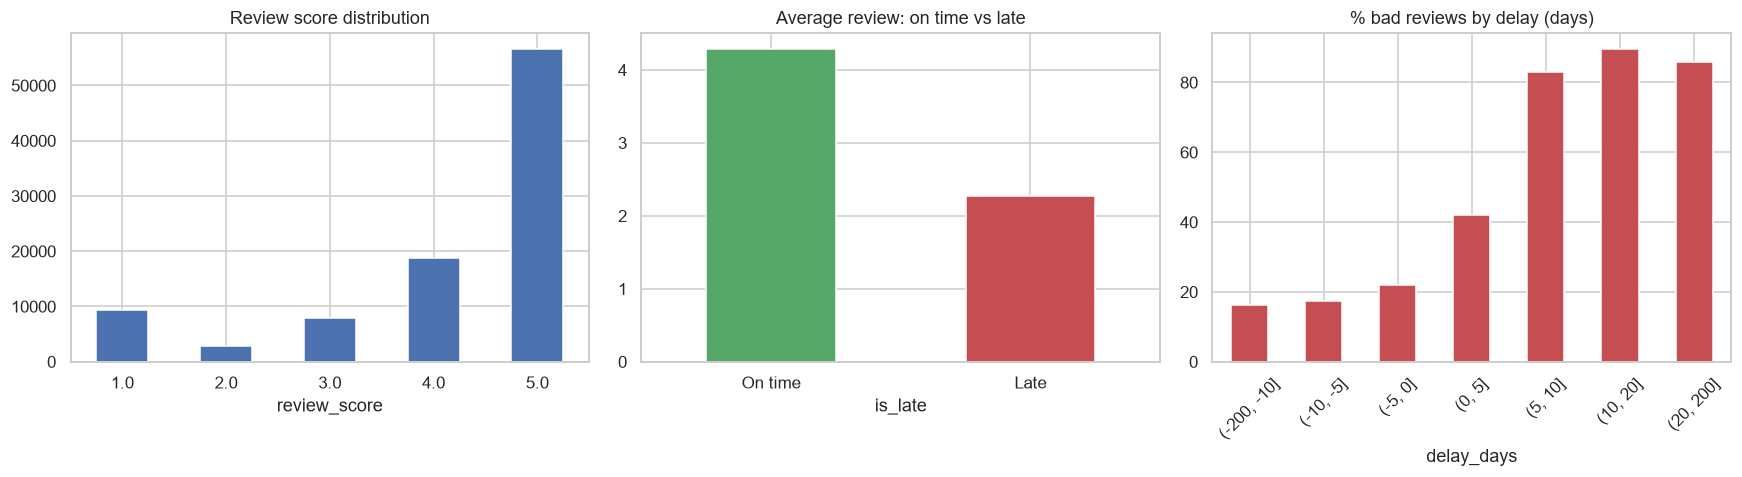

,orders,avg_score,bad_rate
is_late,,,
0.000,89773,4.290,0.173
1.000,6532,2.270,0.733


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
dlv.review_score.value_counts().sort_index().plot.bar(ax=axes[0], color="C0", title="Review score distribution")
dlv.groupby("is_late").review_score.mean().rename({0: "On time", 1: "Late"}).plot.bar(ax=axes[1], color=["C2", "C3"], title="Average review: on time vs late")
bins = pd.cut(dlv.delay_days, [-200, -10, -5, 0, 5, 10, 20, 200])
dlv.groupby(bins, observed=True).bad_review.mean().mul(100).plot.bar(ax=axes[2], color="C3", title="% bad reviews by delay (days)")
for ax in axes: ax.tick_params(axis="x", rotation=0)
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIG / "reviews.png"); plt.show()
dlv.groupby("is_late").agg(orders=("order_id", "size"), avg_score=("review_score", "mean"), bad_rate=("bad_review", "mean"))

## 8. Payments

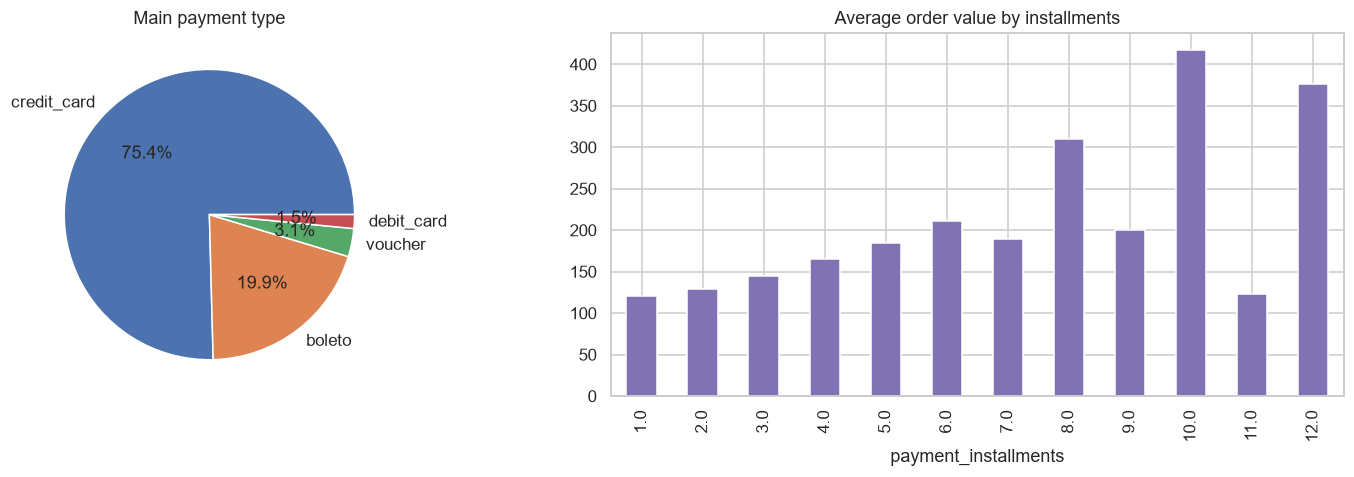

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
master.payment_type.value_counts().plot.pie(ax=axes[0], autopct="%1.1f%%", title="Main payment type"); axes[0].set_ylabel("")
master.groupby(master.payment_installments.clip(upper=12)).order_value.mean().plot.bar(ax=axes[1], color="C4", title="Average order value by installments")
plt.tight_layout(); plt.savefig(FIG / "payments.png"); plt.show()

Credit card dominates (~75%); customers split larger purchases into more installments (common in Brazil).

## 9. Hypothesis testing
Significance level **α = 0.05** for every test. With ~95k rows almost everything is "significant", so we also report **effect sizes**.

In [14]:
from scipy import stats
results = []

def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

# H1: late delivery and bad review are independent (chi-square test of independence)
ct = pd.crosstab(dlv.is_late, dlv.bad_review); chi2, p, dof, _ = stats.chi2_contingency(ct)
results.append(["Chi-square: is_late × bad_review", chi2, p, f"Cramér's V = {cramers_v(ct):.3f}"])
display(ct)

# H2: payment type and bad review are independent
ct2 = pd.crosstab(dlv.payment_type, dlv.bad_review); chi2, p, *_ = stats.chi2_contingency(ct2)
results.append(["Chi-square: payment_type × bad_review", chi2, p, f"Cramér's V = {cramers_v(ct2):.3f}"])

# H3: delivery time is the same for good and bad reviews (Welch t-test + Mann-Whitney U)
g, b = dlv.loc[dlv.bad_review == 0, "actual_delivery_days"], dlv.loc[dlv.bad_review == 1, "actual_delivery_days"]
t, p = stats.ttest_ind(b, g, equal_var=False)
d = (b.mean() - g.mean()) / np.sqrt((b.var() + g.var()) / 2)
results.append(["Welch t-test: delivery days (bad vs good)", t, p, f"Cohen's d = {d:.3f}; means {b.mean():.1f} vs {g.mean():.1f}"])
u, p = stats.mannwhitneyu(b, g)
results.append(["Mann-Whitney U: delivery days (bad vs good)", u, p, "non-parametric check"])

# H4: average review is equal across the top 10 states (ANOVA + Kruskal-Wallis)
top = dlv.customer_state.value_counts().index[:10]
groups = [dlv.loc[dlv.customer_state == s, "review_score"].dropna() for s in top]
f, p = stats.f_oneway(*groups); results.append(["One-way ANOVA: review score across 10 states", f, p, ""])
h, p = stats.kruskal(*groups); results.append(["Kruskal-Wallis: review score across 10 states", h, p, ""])

# H5: freight value correlates with distance
r, p = stats.pearsonr(dlv.distance_km, dlv.total_freight); results.append(["Pearson: distance × freight", r, p, f"r = {r:.3f}"])
rho, p = stats.spearmanr(dlv.distance_km, dlv.actual_delivery_days); results.append(["Spearman: distance × delivery days", rho, p, f"ρ = {rho:.3f}"])

res = pd.DataFrame(results, columns=["test", "statistic", "p_value", "effect / note"])
res["reject H0 (α=0.05)"] = res.p_value < 0.05
res

bad_review,0.000,1.000
is_late,,
0.000,73791,15490
1.000,1703,4676


,test,statistic,p_value,effect / note,reject H0 (α=0.05)
0,Chi-square: is_late × bad_review,"11,200.335",0.000,Cramér's V = 0.342,True
1,Chi-square: payment_type × bad_review,8.793,0.032,Cramér's V = 0.010,True
2,Welch t-test: delivery days (bad vs good),67.224,0.000,Cohen's d = 0.614; means 17.9 vs 11.1,True
3,Mann-Whitney U: delivery days (bad vs good),"999,926,642.500",0.000,non-parametric check,True
4,One-way ANOVA: review score across 10 states,68.023,0.000,,True
5,Kruskal-Wallis: review score across 10 states,429.939,0.000,,True
6,Pearson: distance × freight,0.316,0.000,r = 0.316,True
7,Spearman: distance × delivery days,0.542,0.000,ρ = 0.542,True


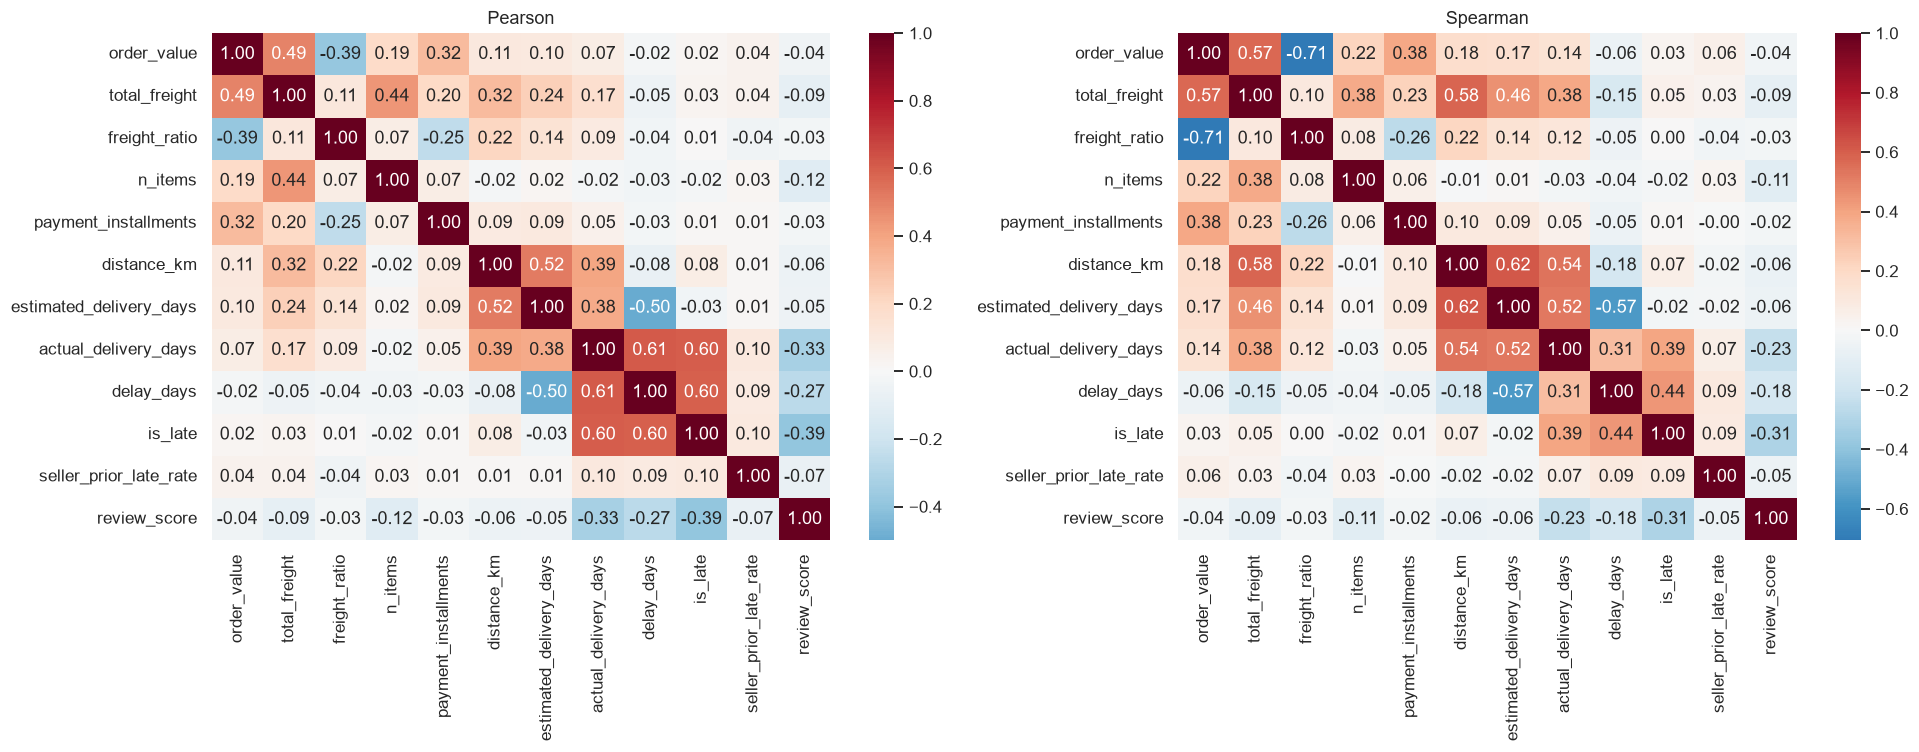

In [15]:
cols = ["order_value", "total_freight", "freight_ratio", "n_items", "payment_installments", "distance_km",
        "estimated_delivery_days", "actual_delivery_days", "delay_days", "is_late", "seller_prior_late_rate", "review_score"]
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(dlv[cols].corr(method="pearson"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(dlv[cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout(); plt.savefig(FIG / "correlation.png"); plt.show()

## 10. Key insights
1. **Delivery is the #1 driver of satisfaction.** Late orders average ≈2.5★ vs ≈4.3★ on time; bad-review rate jumps from ~18% to ~70%+ (χ² test, Cramér's V ≈ 0.3 — moderate-to-strong effect).
2. Bad-review orders took significantly longer to arrive (Welch t, large effect).
3. Distance strongly drives freight cost and delivery time; North/North-East states (RR, AP, AM, AL) wait 2–3× longer than SP.
4. Business grew fast through 2017; Black Friday and Feb–Mar 2018 caused delivery overloads.
5. Only ~3% of customers repeat → improving delivery reliability is the lever for retention.

These motivate the two models: **predict late deliveries at purchase time** and **predict dissatisfied customers after delivery**.